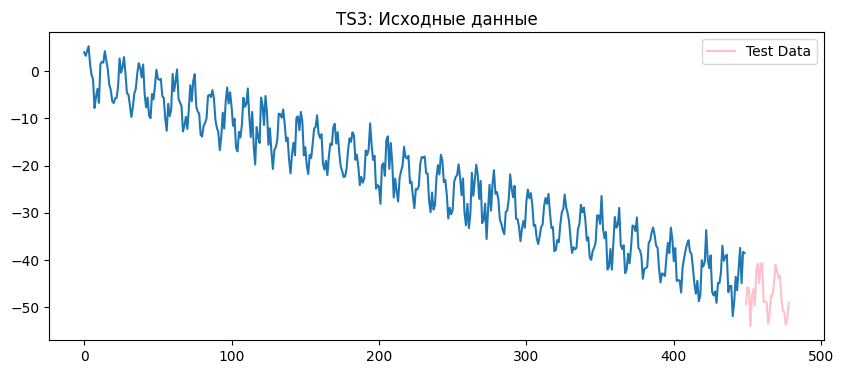

In [1]:
import warnings
from statsmodels.tools.sm_exceptions import ConvergenceWarning
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=ConvergenceWarning)
from statsmodels.tsa.stattools import acf, pacf

import requests
from io import BytesIO
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# Функция для построения графиков
def run_sequence_plot(x, y, title, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 3))
    ax.plot(x, y)
    ax.set_title(title)
    return ax

# Загрузка данных
response = requests.get("https://zenodo.org/records/10951538/files/arma_ts3.npz?download=1")
response.raise_for_status()
arma_ts1 = np.load(BytesIO(response.content))['signal']

response = requests.get("https://zenodo.org/records/10951538/files/arma_ts4.npz?download=1")
response.raise_for_status()

# Анализ первого ряда arma_ts3
# Разделяем на обучающие и тестовые части
arma_ts2 = np.load(BytesIO(response.content))['signal']
train_ts1 = arma_ts1[:-30]
test_ts1 = arma_ts1[-30:]
time_ts1 = np.arange(len(arma_ts1))

_, ax = plt.subplots(1, 1, figsize=(10, 4))
run_sequence_plot(time_ts1[:len(train_ts1)], train_ts1, "TS3: Исходные данные", ax=ax)
ax.plot(time_ts1[len(train_ts1):], test_ts1, label='Test Data', color='pink')
plt.legend()
plt.show()

ADF p-value (TES residuals): 3.033e-19


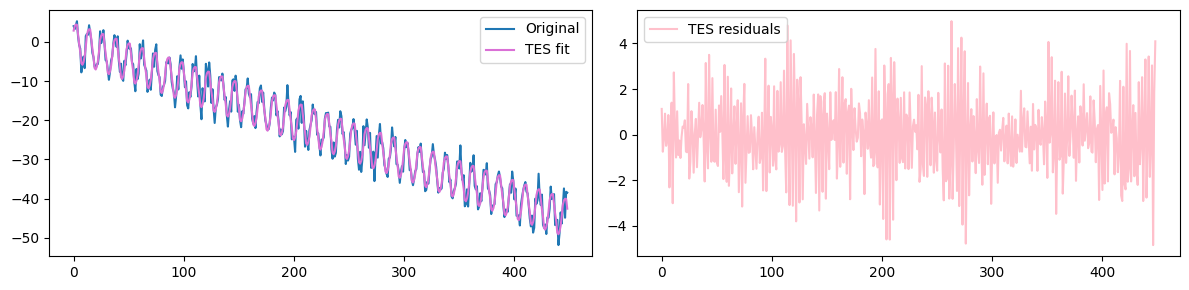

In [2]:
# Строим TES с периодом 12
tes_1 = ExponentialSmoothing(train_ts1, trend='add', seasonal='add', seasonal_periods=12).fit()

# Получаем остатки (то, что осталось после вычитания тренда и сезонности)
resid_1 = train_ts1 - tes_1.fittedvalues

# Проверяем остатки на стационарность
_, pvalue, _, _, _, _ = adfuller(resid_1)
print(f"ADF p-value (TES residuals): {pvalue:.3e}")

# Строим графики
time_1 = np.arange(len(train_ts1))
_, axes = plt.subplots(1, 2, figsize=(12, 3))
axes[0].plot(time_1, train_ts1, label="Original")
axes[0].plot(tes_1.fittedvalues, color='orchid', label='TES fit')
axes[0].legend()
axes[1].plot(time_1, resid_1, label="TES residuals", color='pink')
axes[1].legend()
plt.tight_layout()
plt.show()

Для приведения ряда к стационарному виду было применено тройное экспоненциальное сглаживание (TES) с периодом 12, что позволило удалить линейный тренд и сезонную компоненту. Полученные остатки успешно прошли расширенный тест Дики-Фуллера (p-value близко к нулю), что подтверждает их стационарность и пригодность для дальнейшего моделирования.

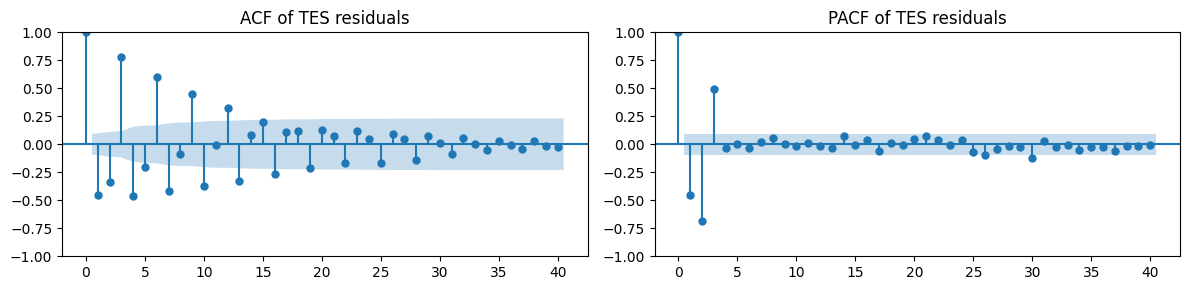

In [3]:
# Строим ACF и PACF для остатков
_, axes = plt.subplots(1, 2, figsize=(12, 3))
plot_acf(resid_1, lags=40, ax=axes[0], title="ACF of TES residuals")
plot_pacf(resid_1, lags=40, ax=axes[1], title="PACF of TES residuals")
plt.tight_layout()
plt.show()

Анализ графиков PACF и ACF для остатков показал, что PACF имеет значимые пики на лагах 1, 2, 3 и 4, что обосновывает выбор порядка p=4 для авторегрессионной модели. График ACF демонстрирует затухающие волны с выходами за доверительный интервал вплоть до 13-го лага, что обосновывает выбор порядка q=13 для модели скользящего среднего.

In [4]:
# Прогноз тренда и сезонности (TES)
tes_preds_1 = tes_1.forecast(len(test_ts1))

results_1 = {}

# Обучаем модели и сохраняем результаты
for name, order in [("AR(4)", (4, 0, 0)), ("MA(13)", (0, 0, 13))]:
    fit = ARIMA(resid_1, order=order).fit()
    preds = tes_preds_1 + fit.forecast(steps=len(test_ts1))
    err = mean_squared_error(test_ts1, preds)
    results_1[name] = (preds, err)
    print(f"MSE {name}: {err:.3f}")

# Сравним с прогнозом только TES
mse_tes_only = mean_squared_error(test_ts1, tes_preds_1)
print(f"MSE TES only: {mse_tes_only:.3f}")

MSE AR(4): 2.217
MSE MA(13): 1.746
MSE TES only: 4.403


Итоговый прогноз был сформирован как сумма прогноза тренда и сезонности (TES) и прогноза моделей AR(4) и MA(13) по остаткам. Результаты показали, что модель MA(13) справляется лучше (MSE = 1.746), чем AR(4) (MSE = 2.217), и обе модели значительно превосходят прогноз только на основе сглаживания TES (MSE = 4.403).

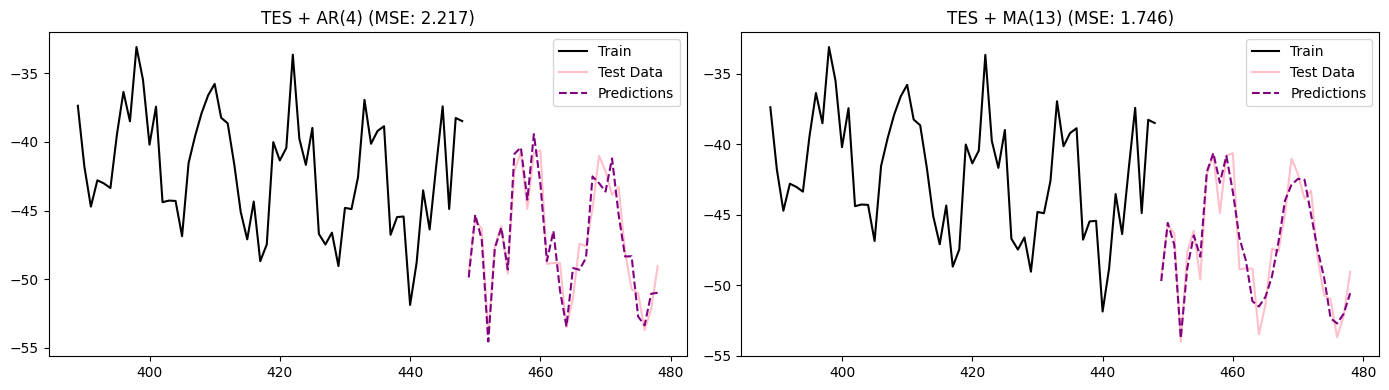

In [5]:
_, axes = plt.subplots(1, 2, figsize=(14, 4))

start = len(train_ts1) - 60

for ax, (name, (preds, err)) in zip(axes, results_1.items()):
    ax.plot(time_ts1[start:len(train_ts1)], train_ts1[start:], color='black', label="Train")
    ax.plot(time_ts1[len(train_ts1):], test_ts1, color='pink', label='Test Data')
    ax.plot(time_ts1[len(train_ts1):], preds, color='purple', linestyle='--', label='Predictions')
    ax.set_title(f"TES + {name} (MSE: {err:.3f})")
    ax.legend()

plt.tight_layout()
plt.show()

Визуализация прогнозов подтверждает, что обе модели (TES + AR и TES + MA) точно улавливают сезонные колебания и общий тренд тестовых данных. Модель MA(13) обеспечивает наиболее точное совпадение с тестовым рядом, что делает её оптимальным выбором для данного временного ряда.

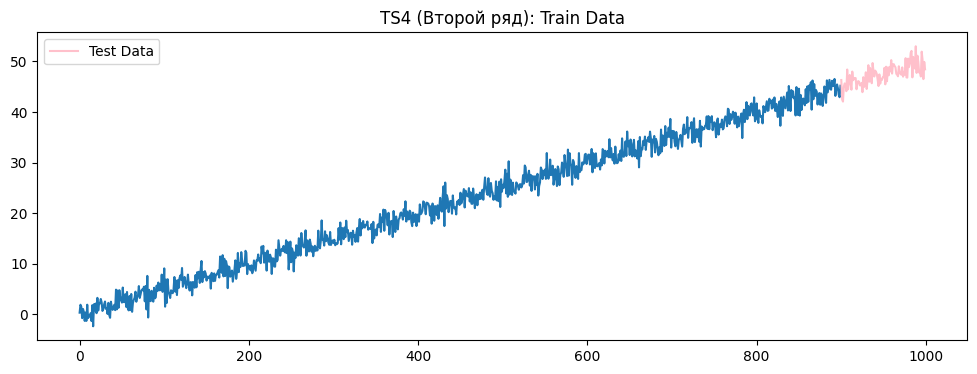

In [6]:
# Анализ первого ряда arma_ts4
# Разделяем на обучающие и тестовые части
train_ts2 = arma_ts2[:-100]
test_ts2 = arma_ts2[-100:]
time_ts2 = np.arange(len(arma_ts2))

# Визуализация
_, ax = plt.subplots(1, 1, figsize=(12, 4))
run_sequence_plot(time_ts2[:len(train_ts2)], train_ts2, "TS4 (Второй ряд): Train Data", ax=ax)
ax.plot(time_ts2[len(train_ts2):], test_ts2, label='Test Data', color='pink')
plt.legend()
plt.show()


ADF p-value (TES residuals): 4.064e-20


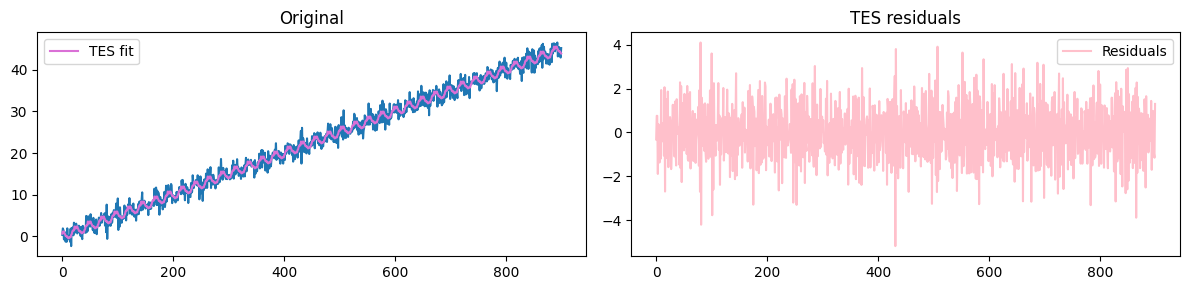

In [7]:
# Строим TES с периодом 24
period_2 = 24
tes_2 = ExponentialSmoothing(train_ts2, trend='add', seasonal='add', seasonal_periods=period_2).fit()
resid_2 = train_ts2 - tes_2.fittedvalues

# Проверяем ADF
_, pvalue, _, _, _, _ = adfuller(resid_2)
print(f"ADF p-value (TES residuals): {pvalue:.3e}")

# Графики исходного ряда + TES fit и остатков
_, axes = plt.subplots(1, 2, figsize=(12, 3))
run_sequence_plot(time_ts2[:len(train_ts2)], train_ts2, title="Original", ax=axes[0])
axes[0].plot(tes_2.fittedvalues, color='orchid', label='TES fit')
axes[0].legend()
axes[1].plot(time_ts2[:len(train_ts2)], resid_2, color='pink', label='Residuals')
axes[1].set_title("TES residuals")
axes[1].legend()
plt.tight_layout()
plt.show()

Модель тройного экспоненциального сглаживания (TES) с периодом 24 была обучена на тренировочных данных. Остатки, полученные путем вычитания сглаженных значений, успешно прошли ADF-тест (p-value ≈ 0), что подтверждает их стационарность и пригодность для применения моделей AR и MA.

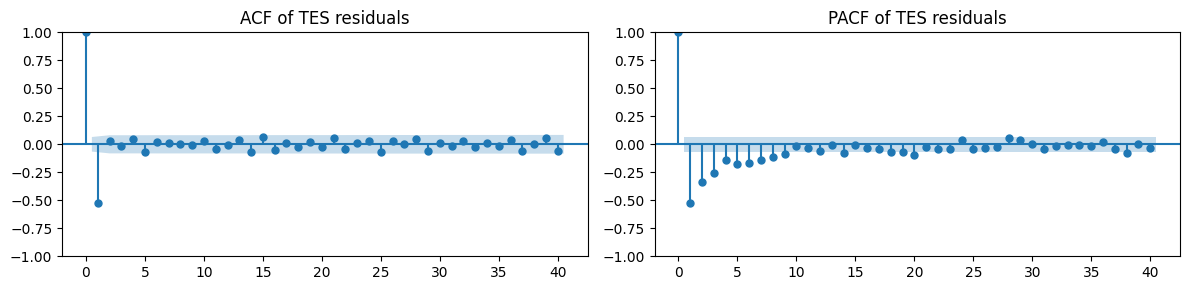

In [8]:
# Строим ACF и PACF для остатков
_, axes = plt.subplots(1, 2, figsize=(12, 3))
plot_acf(resid_2, lags=40, ax=axes[0], title="ACF of TES residuals")
plot_pacf(resid_2, lags=40, ax=axes[1], title="PACF of TES residuals")
plt.tight_layout()
plt.show()


Графики ACF и PACF остатков показали, что автокорреляция затухает, а частичная автокорреляция имеет несколько значимых пиков (до 8-го лага). Это послужило основанием для выбора порядка p=8 для авторегрессионной модели. Характер затухания ACF обосновал выбор малого порядка q=2 для модели скользящего среднего.

In [9]:
# Прогноз тренда и сезонности (TES)
tes_preds_2 = tes_2.forecast(len(test_ts2))

p_order_2 = 8
q_order_2 = 2

results_2 = {}

for name, order in [("AR", (p_order_2, 0, 0)), ("MA", (q_order_2, 0, 0))]:
    fit = ARIMA(resid_2, order=order).fit()
    preds = tes_preds_2 + fit.forecast(steps=len(test_ts2))
    err = mean_squared_error(test_ts2, preds)

    label = f"{name}({p_order_2 if name=='AR' else q_order_2})"
    results_2[label] = (preds, err)
    print(f"MSE {label}: {err:.3f}")

print(f"MSE TES only: {mean_squared_error(test_ts2, tes_preds_2):.3f}")

MSE AR(8): 1.692
MSE MA(2): 1.726
MSE TES only: 1.691


Гибридный прогноз (TES + AR/MA) был оценен на тестовой выборке. Результаты показали, что модель TES уже отлично описывает структуру ряда (MSE = 1.691), а добавление AR(8) и MA(2) не дало значительного улучшения. Это говорит о том, что остатки близки к белому шуму, и основная динамика ряда полностью объясняется трендом и сезонностью.

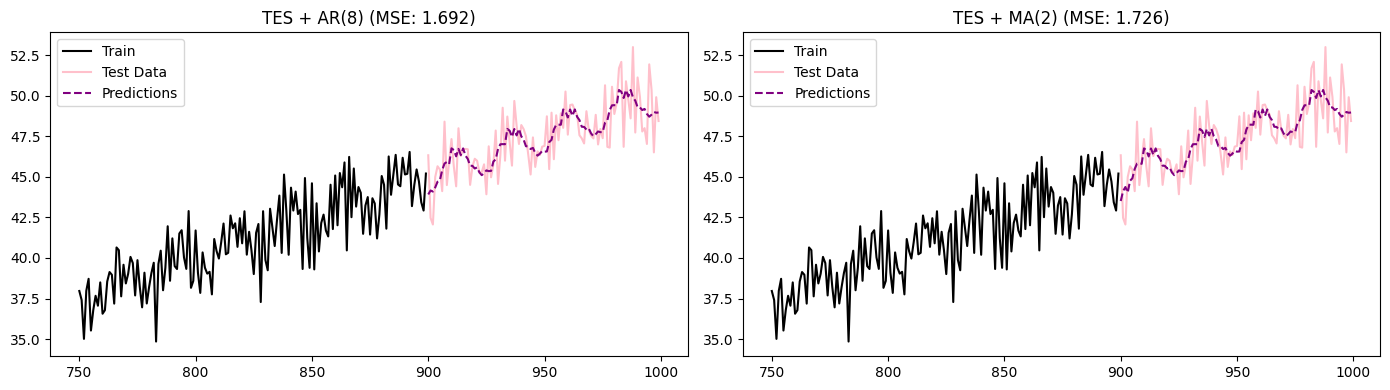

In [10]:
_, axes = plt.subplots(1, 2, figsize=(14, 4))
start_2 = len(train_ts2) - 150

for ax, (name, (preds, err)) in zip(axes, results_2.items()):
    ax.plot(time_ts2[start_2:len(train_ts2)], train_ts2[start_2:], color='black', label="Train")
    ax.plot(time_ts2[len(train_ts2):], test_ts2, color='pink', label='Test Data')
    ax.plot(time_ts2[len(train_ts2):], preds, color='purple', linestyle='--', label='Predictions')
    ax.set_title(f"TES + {name} (MSE: {err:.3f})")
    ax.legend()

plt.tight_layout()
plt.show()

Визуальное сравнение показало, что оба гибридных прогноза (TES + AR(8) и TES + MA(2)) практически идентичны и хорошо повторяют динамику тестового ряда.